In [ ]:
#Meshal Mahnoor

In [ ]:
#imports:
import cv2
import numpy as np
import matplotlib.pyplot as plt
print("OpenCV version:", cv2.__version__)

OpenCV version: 5.0.0


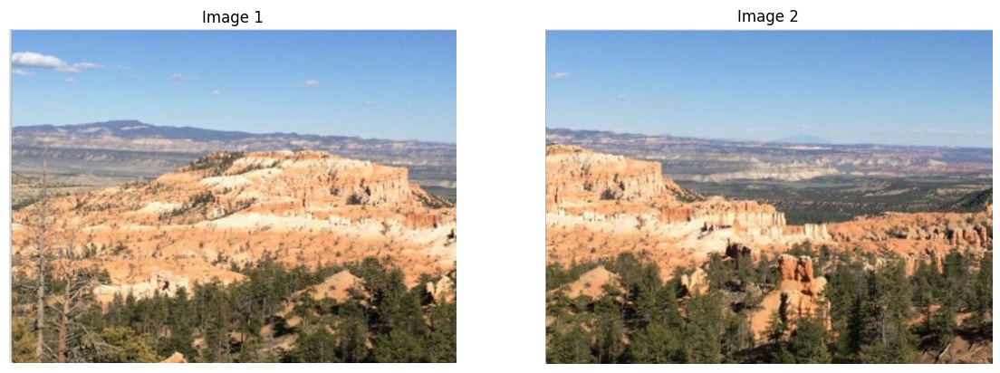

Image 1 size: (365, 488, 3)
Image 2 size: (365, 486, 3)


In [ ]:
# Change these filenames to your own images
image1_path = "il.png"
image2_path = "ir.png"
img1 = cv2.imread(image1_path)
img2 = cv2.imread(image2_path)
if img1 is None or img2 is None:
 raise FileNotFoundError(
"Could not load one or both images. Check the filenames/path."
)

# OpenCV loads images as BGR, so convert to RGB for Matplotlib
img1_rgb = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)
img2_rgb = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.imshow(img1_rgb)
plt.title("Image 1")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(img2_rgb)
plt.title("Image 2")
plt.axis("off")
plt.show()
print("Image 1 size:", img1.shape)
print("Image 2 size:", img2.shape)

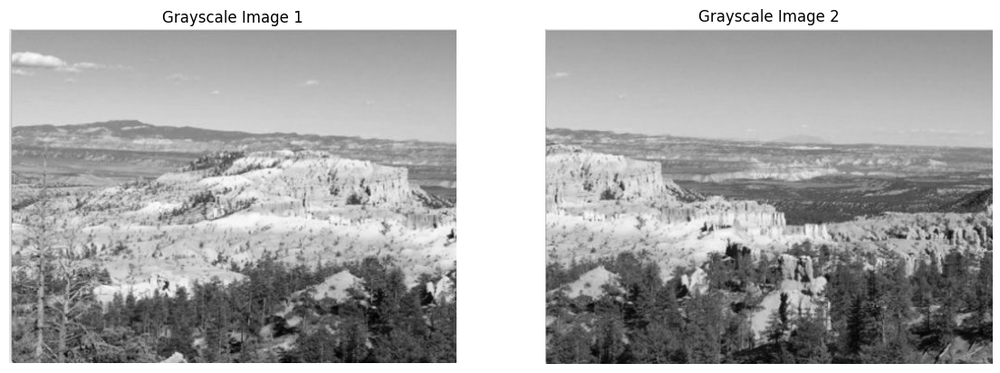

In [ ]:
gray1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.imshow(gray1, cmap="gray")
plt.title("Grayscale Image 1")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gray2, cmap="gray")
plt.title("Grayscale Image 2")
plt.axis("off")
plt.show()

**Question 1:**
Apply Harris corner detection to your own image and display the detected corners. Then try three
different threshold values and compare the results. Finally, rotate and resize the image and
explain why Harris is not scale invariant.

Scaled up size: 488 × 365


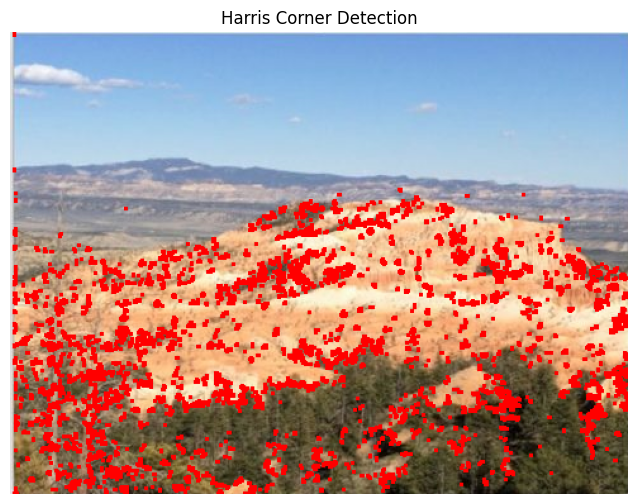

In [ ]:
# Convert to float32 because cv2.cornerHarris expects this type
gray1_float = np.float32(gray1)
# Harris parameters
block_size = 2
kernel_size = 3
k = 0.04
harris_response = cv2.cornerHarris(
gray1_float,
block_size,
kernel_size,
k
)
# Dilate the response so detected corner regions become larger and easier to see
harris_response = cv2.dilate(harris_response, None)
# Keep pixels whose Harris response is greater than 1% of the maximum response in the image.
# This controls how strong a response must be to be considered a detected corner.
threshold = 0.01 * harris_response.max()
up_h, up_w = gray1_float.shape[:2]
print("Scaled up size:", up_w, "×", up_h)
harris_img = img1_rgb.copy()
harris_img[harris_response > threshold] = [255, 0, 0]
plt.figure(figsize=(9, 6))
plt.imshow(harris_img)
plt.title("Harris Corner Detection")
plt.axis("off")
plt.show()

Scaled up size: 732 × 548


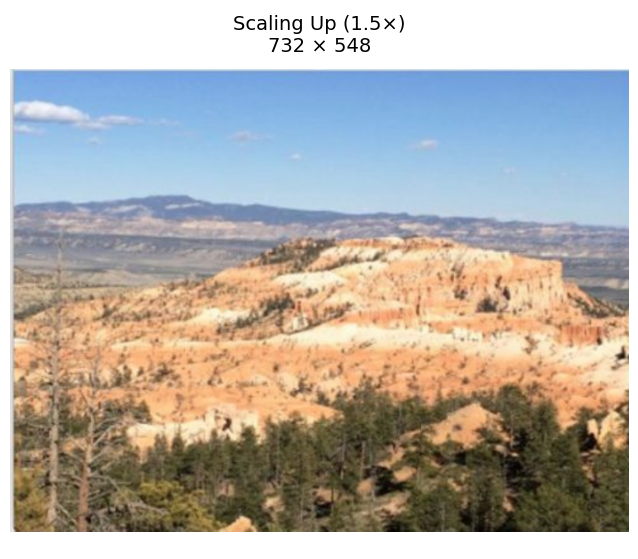

In [ ]:
#lets rotate and scale the image to see how Harris's corner detection fails for invariance:
# ============================
# SCALING
# ============================
# Scale up by 1.5×
scaled_up = cv2.resize(
img1_rgb,
None,
fx=1.5,
fy=1.5,
interpolation=cv2.INTER_LINEAR
)

# Get dimensions
up_h, up_w = scaled_up.shape[:2]
print("Scaled up size:", up_w, "×", up_h)

# ============================
# DISPLAY AT ACTUAL RELATIVE SIZES
# ============================
fig, ax = plt.subplots(figsize=(18, 7))
# Position of each image
x1 = 0
x2 = w + 80
x3 = x2 + up_w + 80
# Display images using their actual dimensions
ax.imshow(
scaled_up,
extent=[x2, x2 + up_w, 0, up_h]
)

# Titles
ax.text(
x2 + up_w/2,
up_h + 20,
f"Scaling Up (1.5×)\n{up_w} × {up_h}",
ha="center",
fontsize=14
)

# Make sure the actual proportions are preserved
ax.set_aspect("equal")
# Remove axes
ax.axis("off")
# Set limits so all images are visible
ax.set_ylim(-20, up_h + 70)
plt.show()
scaled_up_float = np.float32(scaled_up)

Scaled up size: 732 × 548


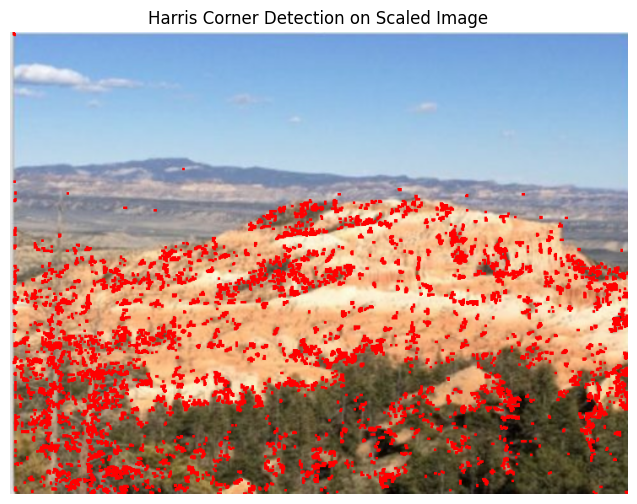

In [ ]:
#lets apply harris filter on a scaled
# Convert to grayscale first because cornerHarris requires a single-channel image
scaled_up_gray = cv2.cvtColor(scaled_up, cv2.COLOR_RGB2GRAY)
scaled_up_float = np.float32(scaled_up_gray)

# Harris parameters
block_size = 2
kernel_size = 3
k = 0.04
harris_response = cv2.cornerHarris(
    scaled_up_float,
    block_size,
    kernel_size,
    k
)

# Dilate the response so detected corner regions become larger and easier to see
harris_response = cv2.dilate(harris_response, None)

# Keep pixels whose Harris response is greater than 1% of the maximum response in the image.
# This controls how strong a response must be to be considered a detected corner.
threshold = 0.01 * harris_response.max()
up_h, up_w = scaled_up_float.shape[:2]
print("Scaled up size:", up_w, "×", up_h)

# Color the corners red on the original RGB scaled up image
harris_img = scaled_up.copy()
harris_img[harris_response > threshold] = [255, 0, 0]

plt.figure(figsize=(9, 6))
plt.imshow(harris_img)
plt.title("Harris Corner Detection on Scaled Image")
plt.axis("off")
plt.show()

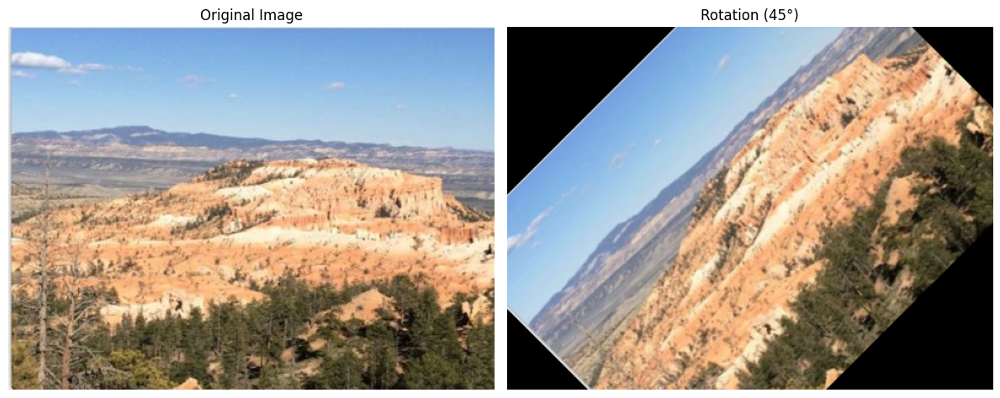

In [ ]:
#rotating the image:
# ============================
# ROTATION
# ============================
# Get image dimensions
h, w = img1_rgb.shape[:2]
# Rotation angle
angle = 45
# Rotation matrix
center = (w // 2, h // 2)
M = cv2.getRotationMatrix2D(
center,
angle,
1.0
)
# Rotate the image
rotated = cv2.warpAffine(
img1_rgb,
M,
(w, h)
)
# ============================
# DISPLAY
# ============================
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(img1_rgb)

plt.title("Original Image")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(rotated)
plt.title("Rotation (45°)")
plt.axis("off")
plt.tight_layout()
plt.show()

Scaled up size: 488 × 365


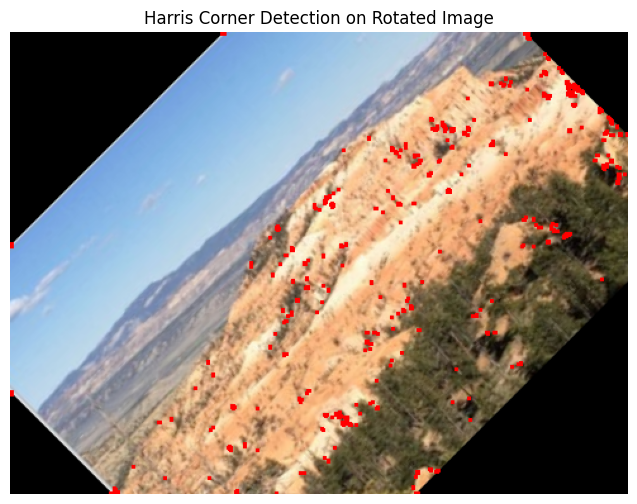

In [ ]:
#lets apply harris filter on a scaled
# Convert to grayscale first because cornerHarris requires a single-channel image
rotated_gray = cv2.cvtColor(rotated, cv2.COLOR_RGB2GRAY)
rotated_float = np.float32(rotated_gray)

# Harris parameters
block_size = 2
kernel_size = 3
k = 0.04
harris_response = cv2.cornerHarris(
    rotated_float,
    block_size,
    kernel_size,
    k
)

# Dilate the response so detected corner regions become larger and easier to see
harris_response = cv2.dilate(harris_response, None)

# Keep pixels whose Harris response is greater than 1% of the maximum response in the image.
# This controls how strong a response must be to be considered a detected corner.
threshold = 0.01 * harris_response.max()
up_h, up_w = rotated_float.shape[:2]
print("Scaled up size:", up_w, "×", up_h)

# Color the corners red on the original RGB rotated image (3 channels)
harris_img = rotated.copy()
harris_img[harris_response > threshold] = [255, 0, 0]

plt.figure(figsize=(9, 6))
plt.imshow(harris_img)
plt.title("Harris Corner Detection on Rotated Image")
plt.axis("off")
plt.show()

##**Task 1 End**

**Question 2:**
Take two overlapping photos and match their SIFT features using Lowe's ratio test. Estimate the
homography with RANSAC, report the inlier count, and stitch the images into a panorama.

In [ ]:
#sift usage for invariance
sift = cv2.SIFT_create()
keypoints1, descriptors1 = sift.detectAndCompute(gray1, None)
keypoints2, descriptors2 = sift.detectAndCompute(gray2, None)
print("Number of keypoints in Image 1:", len(keypoints1))
print("Number of keypoints in Image 2:", len(keypoints2))
print("Descriptor shape for Image 1:", descriptors1.shape)
print("Descriptor shape for Image 2:", descriptors2.shape)

Number of keypoints in Image 1: 2535
Number of keypoints in Image 2: 2237
Descriptor shape for Image 1: (2535, 128)
Descriptor shape for Image 2: (2237, 128)


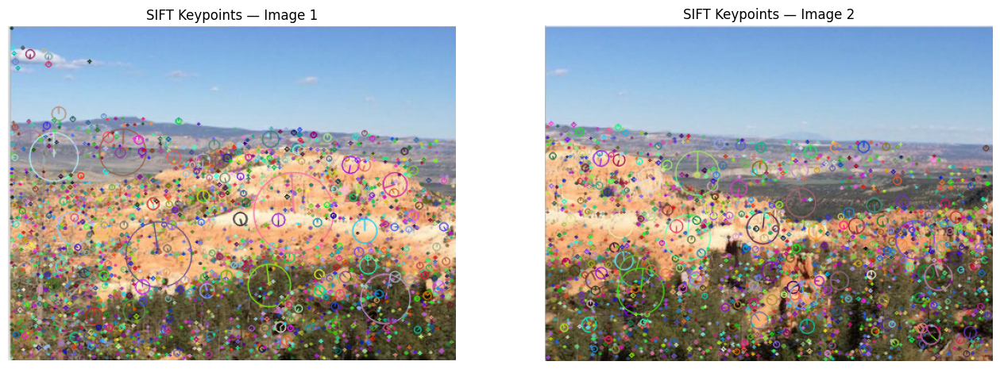

In [ ]:
# Visualize SIFT keypoints
sift_vis1 = cv2.drawKeypoints(
img1_rgb,
keypoints1,
None, # telling OpenCV to create the output image itself
flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)
sift_vis2 = cv2.drawKeypoints(
img2_rgb,
keypoints2,
None,
flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)
plt.figure(figsize=(16, 7))
# (rows, columns, position)
plt.subplot(1, 2, 1)
plt.imshow(sift_vis1)
plt.title("SIFT Keypoints — Image 1")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(sift_vis2)
plt.title("SIFT Keypoints — Image 2")
plt.axis("off")
plt.show()

In [ ]:
# Inspect the first keypoint and its descriptor
print("First keypoint:")
print(keypoints1[0])
print("\nFirst descriptor:")
print(descriptors1[0])
print("\nDescriptor length:")
print(len(descriptors1[0]))

First keypoint:
< cv2.KeyPoint 0x7ac996b878a0>

First descriptor:
[  0.   0.   1.   5.   4.  17.  45.  31.  37.   4.   4.   3.   1.  13.
  34.  32. 161.   6.   1.   0.   0.   0.   1.  23.  55.   1.   0.   0.
   0.   0.   0.   1.   2.   8.  21.  49.  10.   6.  19.   6.  52.  15.
  25.  14.   2.   6.  19.   8. 161.  18.   2.   1.   0.   0.   1.   8.
  66.   3.   0.   0.   0.   0.   0.   0.  11.  19.  96.  13.   2.   4.
  37.  21.  34.  27. 116.  12.   2.  21.  48.  19. 161.  59.  14.   1.
   0.   1.   4.  25.  66.   3.   0.   0.   0.   0.   0.   1.   1.  15.
 161.  64.   6.   0.   2.   5.  37.  85. 161.   8.   0.   6.   5.   6.
 161. 159.  28.   0.   0.   0.   0.   4.  73.   6.   0.   0.   0.   0.
   0.   1.]

Descriptor length:
128


In [ ]:
# Create a Brute-Force matcher
bf = cv2.BFMatcher(cv2.NORM_L2, crossCheck=False)
# Find the two nearest neighbors for every descriptor
matches_knn = bf.knnMatch(descriptors1, descriptors2, k=2)
print("Number of descriptor pairs examined:", len(matches_knn))

Number of descriptor pairs examined: 2535


In [ ]:
ratio_threshold = 0.75
good_matches = []
for pair in matches_knn:

 if len(pair) == 2:
  m, n = pair
  if m.distance < ratio_threshold * n.distance:
    good_matches.append(m)
print("Total candidate matches:", len(matches_knn))
print("Good matches after ratio test:", len(good_matches))

Total candidate matches: 2535
Good matches after ratio test: 457


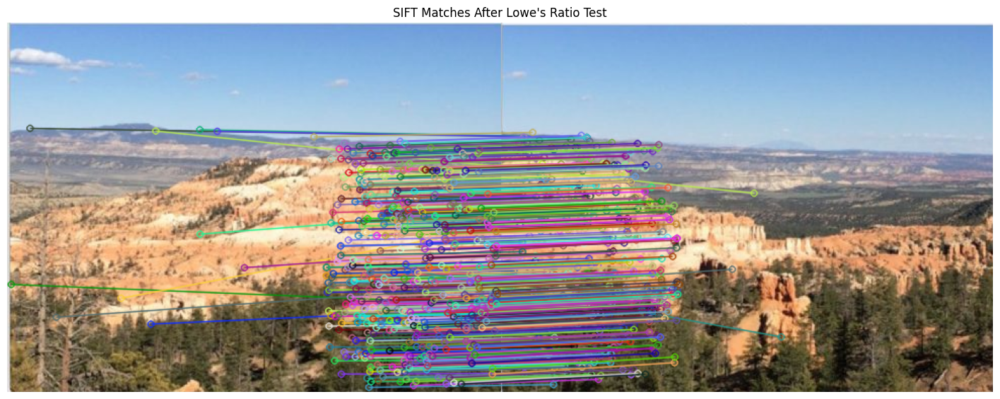

In [ ]:
# Visualize the good matches
match_img = cv2.drawMatches(
img1_rgb,
keypoints1,
img2_rgb,
keypoints2,
good_matches,
None,
flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)
plt.figure(figsize=(18, 8))
plt.imshow(match_img)
plt.title("SIFT Matches After Lowe's Ratio Test")
plt.axis("off")
plt.show()

In [ ]:
if len(good_matches) < 4:
 raise ValueError(
"At least 4 good matches are required to estimate a homography."
)
# m.queryIdx → index of the matched keypoint in Image 1
# keypoints1[...] → gets that particular SIFT keypoint
# .pt → gets its pixel coordinates (x, y)
src_pts = np.float32([
keypoints1[m.queryIdx].pt for m in good_matches
]).reshape(-1, 1, 2)
dst_pts = np.float32([
keypoints2[m.trainIdx].pt for m in good_matches
]).reshape(-1, 1, 2)
print("Source point array shape:", src_pts.shape)
print("Destination point array shape:", dst_pts.shape)

Source point array shape: (457, 1, 2)
Destination point array shape: (457, 1, 2)


In [ ]:
# Estimate homography using RANSAC
H, mask = cv2.findHomography(
src_pts,
dst_pts,
cv2.RANSAC,
5.0 # maximum allowed reprojection error (in pixels)
)
if H is None:
 raise RuntimeError("Homography could not be estimated.")
# Convert from 1 Column array [[1], [0], [1], ...] to 1D array [1, 0, 1, ...]
mask = mask.ravel()
inlier_matches = [
# An inlier is a match that agrees with the estimated homography
match for match, keep in zip(good_matches, mask) if keep
]
outlier_matches = [
# An outlier does not agree sufficiently with the estimated homography
match for match, keep in zip(good_matches, mask) if not keep
]
print("Total good matches:", len(good_matches))
print("RANSAC inliers:", len(inlier_matches))
print("RANSAC outliers:", len(outlier_matches))

print("Inlier ratio:", len(inlier_matches) / len(good_matches))
print("\nHomography matrix:\n", H)

Total good matches: 457
RANSAC inliers: 444
RANSAC outliers: 13
Inlier ratio: 0.9715536105032823

Homography matrix:
 [[ 1.19431107e+00  1.97708380e-02 -3.74528291e+02]
 [ 5.56519337e-02  1.15880234e+00 -2.86723177e+01]
 [ 3.98639163e-04  3.10414181e-06  1.00000000e+00]]


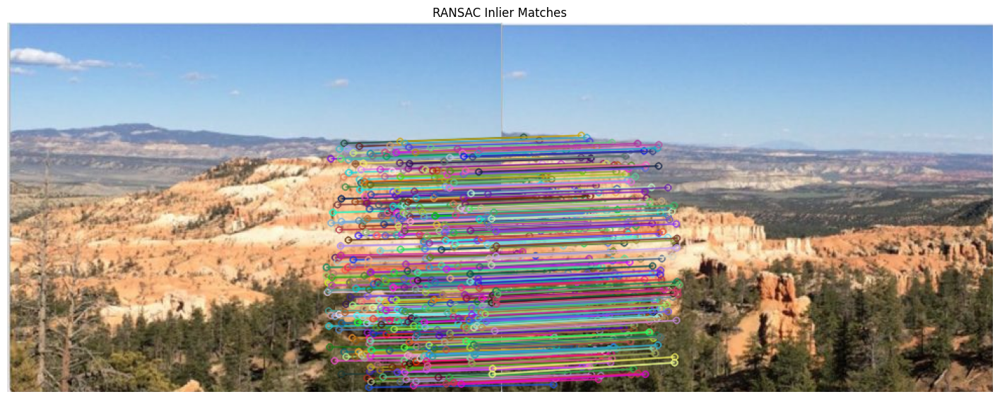

In [ ]:
inlier_img = cv2.drawMatches(
img1_rgb,
keypoints1,
img2_rgb,
keypoints2,
inlier_matches,
None,
flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)
plt.figure(figsize=(18, 8))
plt.imshow(inlier_img)
plt.title("RANSAC Inlier Matches")
plt.axis("off")
plt.show()

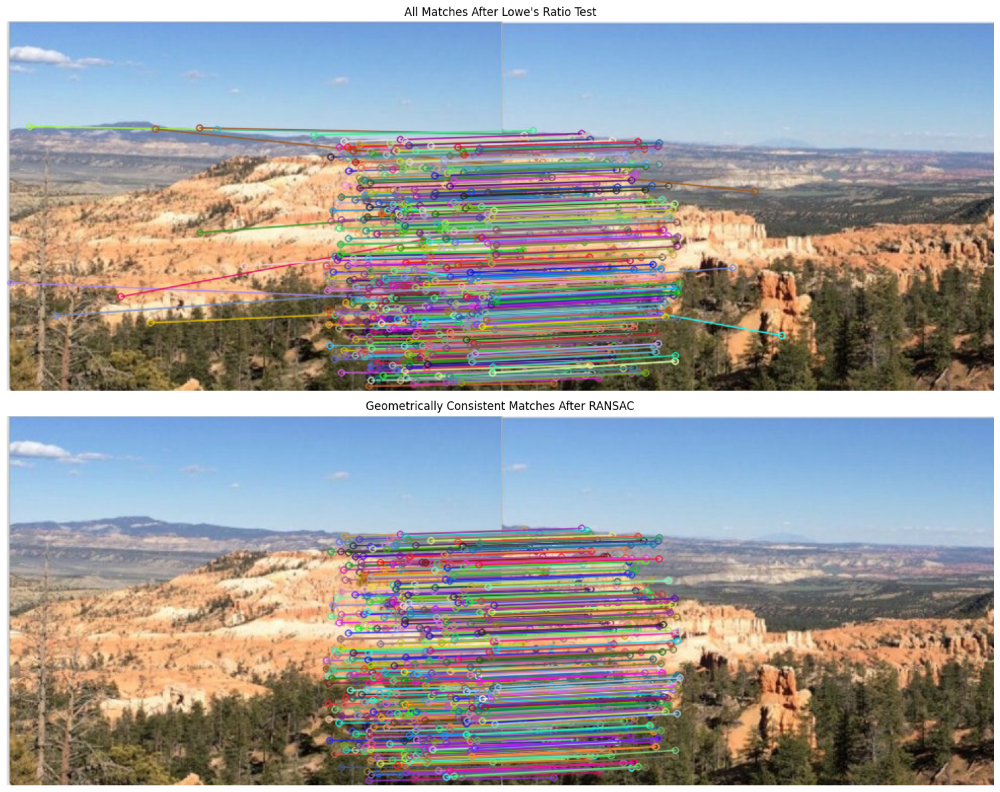

In [ ]:
plt.figure(figsize=(18, 12))
plt.subplot(2, 1, 1)
all_matches_img = cv2.drawMatches(
img1_rgb,
keypoints1,
img2_rgb,
keypoints2,
good_matches,
None,
flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)
plt.imshow(all_matches_img)
plt.title("All Matches After Lowe's Ratio Test")
plt.axis("off")
plt.subplot(2, 1, 2)
inlier_matches_img = cv2.drawMatches(
img1_rgb,
keypoints1,
img2_rgb,
keypoints2,
inlier_matches,
None,
flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)
plt.imshow(inlier_matches_img)
plt.title("Geometrically Consistent Matches After RANSAC")
plt.axis("off")
plt.tight_layout()
plt.show()

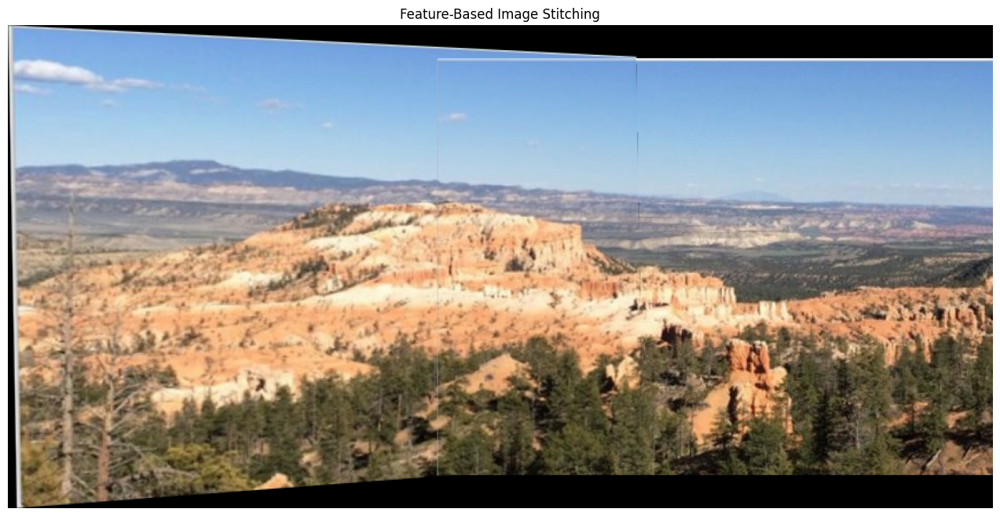

In [ ]:
# image stitching:
def simple_feature_stitch(image1, image2, homography):
    # Homography maps points from image1 -> image2.
    # Therefore we warp image1 into image2's coordinate system.
    # Get the height and width of both images
    h1, w1 = image1.shape[:2]
    h2, w2 = image2.shape[:2]

    # Define the four corner coordinates of Image 1
    corners1 = np.float32([
[0, 0], [w1, 0], [w1, h1], [0, h1]
]).reshape(-1, 1, 2)

    # Define the four corner coordinates of Image 2
    corners2 = np.float32([[0,0], [w2, 0], [w2, h2], [0, h2]
    ]).reshape(-1, 1, 2)

    # This tells us where Image 1's corners will be located in Image 2's coordinate system
    warped_corners1 = cv2.perspectiveTransform(corners1, homography)

    # Combine the corners of both images to determine the complete size of the panorama canvas
    all_corners = np.concatenate([corners2, warped_corners1], axis=0)

    # Find the minimum x and y coordinates required by the panorama
    # floor() ensures the canvas starts far enough to contain all pixels
    xmin, ymin = np.floor(all_corners.min(axis=0).ravel()).astype(int)

    # Find the maximum x and y coordinates required by the panorama
    # ceil() ensures the canvas is large enough to contain all pixels
    xmax, ymax = np.ceil(all_corners.max(axis=0).ravel()).astype(int)

    # Calculate how much the entire panorama needs to be shifted
    # so that negative coordinates become valid canvas coordinates
    tx, ty = -xmin, -ymin
    translation = np.array([
        [1, 0, tx],
        [0, 1, ty],
        [0, 0, 1]
    ], dtype=np.float64)

    # Calculate the width and height of the final panorama canvas
    canvas_w = int(xmax - xmin)
    canvas_h = int(ymax - ymin)

    # Warp image 1 into image 2's coordinate system.
    warped1 = cv2.warpPerspective(
        image1,
        translation @ homography,
        (canvas_w, canvas_h)
    )

    # Place image 2 on the same canvas.
    panorama = warped1.copy()

    # from ty up to ty + h2, ty is how far to shift in the y-direction, Height of Img 2 (h2)
    panorama[ty:ty + h2, tx:tx + w2] = image2

    # Simple overlap blending instead of a hard overwrite.
    warped_mask = cv2.warpPerspective(
        np.ones((h1, w1), dtype=np.uint8),
        translation @ homography,
        (canvas_w, canvas_h)
    )

    image2_mask = np.zeros((canvas_h, canvas_w), dtype=np.uint8)
    image2_mask[ty:ty + h2, tx:tx + w2] = 1
    overlap = (warped_mask > 0) & (image2_mask > 0)

    # Average the overlap to make the educational result less abrupt.
    image2_canvas = np.zeros_like(panorama)
    image2_canvas[ty:ty + h2, tx:tx + w2] = image2

    # Instead of abruptly replacing one image with the other, the overlapping area is blended:
    # 50% Image 1 + 50% Image 2
    panorama[overlap] = (
        0.5 * warped1[overlap] +
        0.5 * image2_canvas[overlap]
    ).astype(np.uint8)

    # Fill regions containing only image 2.
    only_image2 = (warped_mask == 0) & (image2_mask > 0)
    panorama[only_image2] = image2_canvas[only_image2]

    return panorama

# Reuse the homography already estimated above.
panorama = simple_feature_stitch(img1, img2, H)
plt.figure(figsize=(18, 8))
plt.imshow(cv2.cvtColor(panorama, cv2.COLOR_BGR2RGB))
plt.title("Feature-Based Image Stitching")
plt.axis("off")
plt.show()


##**Task 2 End**